In [ ]:
print("hello") #updated test

hello


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

#since we don't need to extract

!cp "/content/drive/MyDrive/Kennydataset_SCF_v2_8192.h5" /content/

'''
# getting data
!cp /content/drive/MyDrive/RadioMLDataset2018.zip /content/
!unzip -q /content/RadioMLDataset2018.zip -d /content/data/
'''

Mounted at /content/drive


'\n# getting data\n!cp /content/drive/MyDrive/RadioMLDataset2018.zip /content/\n!unzip -q /content/RadioMLDataset2018.zip -d /content/data/\n'

In [ ]:
import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt

import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report


device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # basically only using gpu when available
print(f"using device - {device}")

from torch.amp import autocast, GradScaler
scaler = GradScaler(device = 'cuda')


using device - cuda


In [ ]:
import os

save_dir = "/content/drive/MyDrive/RadioML_Models"
os.makedirs(save_dir, exist_ok=True)

model_save_path = os.path.join(save_dir, "SCF8192.pth")

# get rid previous checkpoint so training starts fresh if needed
if os.path.exists(model_save_path):
    os.remove(model_save_path)
    print("Removed old checkpoint. Starting fresh training.")

In [ ]:
print(os.cpu_count())

12


In [ ]:
#!df -h /dev/shm

### Loading the HDF5 Dataset

The dataset is stored in an HDF5 file, which is a common format for storing large amounts of numerical data. We'll use the `h5py` library to open this file and load the IQ samples (X), one-hot encoded class labels (Y), and Signal-to-Noise Ratio (SNR) values (Z).

In [ ]:
#!find /content/drive/MyDrive -name "*.h5"

In [ ]:
file_path = "/content/drive/MyDrive/Kennydataset_SCF_v2_8192.h5"

hdf5_file = h5py.File(file_path, 'r')

X = hdf5_file["X_scf"] # - IQ samples
Y = hdf5_file["Y"] # - one hot class labels
Z = hdf5_file["Z"] # - SNR values

In [ ]:
print("File attributes:")
for k, v in hdf5_file.attrs.items():
    print(k, v)

File attributes:
N_frames_per_snr [1024]
N_samples [8192]
N_snr_levels [26]
N_total [346112]
SCF_N_smooth [8129]
SCF_Nfft [128]
SCF_T [64]
SCF_TB [127.015625]
SCF_alpha_max_hz [50000.]
SCF_axes MATLAB [f, alpha, frame] -> h5py (frame, alpha, f)
SCF_dB_range [40.]
SCF_dalpha_img_hz [781.25]
SCF_dalpha_res_hz [24.60327224]
SCF_df_img_hz [1562.5]
SCF_df_res_hz [3125.]
SCF_estimator SSCA (Roberts, Brown & Loomis 1991), non-conjugate + conjugate
SCF_hop [1]
SCF_overlap [63]
SCF_pool max
SCF_scaling dB below the non-conjugate peak (both channels), clipped to [-dB_range, 0], mapped to [0, 1]
SCF_strip_fft [8192]
SCF_window hamming periodic (channeliser), hamming (smoothing taper)
SNR_definition awgn measured over the full fs band (in-band SNR is higher for narrow signals)
SNR_max [30.]
SNR_min [-20.]
USE_CFO [1]
USE_FADING [1]
USE_PARALLEL [1]
USE_PARALLEL_SCF [1]
USE_PHASE_OFFSET [1]
USE_RS_VAR [1]
USE_TIMING_OFFSET [1]
complete [1]
created 30-Sep-2026 16:05:32
deflate_level [4]
frame_ms [40

In [ ]:
print(f"X shape: {X.shape}")   # signals
print(f"Y shape: {Y.shape}")   # labels
print(f"Z shape: {Z.shape}")   # SNR
print(f"SNR range: {np.unique(Z)}")
print(f"Number of classes: {Y.shape[1]}")

X shape: (346112, 128, 128)
Y shape: (346112, 13)
Z shape: (346112, 1)
SNR range: [-20. -18. -16. -14. -12. -10.  -8.  -6.  -4.  -2.   0.   2.   4.   6.
   8.  10.  12.  14.  16.  18.  20.  22.  24.  26.  28.  30.]
Number of classes: 13


In [ ]:
# X into memory
print("Loading X into memory")
X_loaded = hdf5_file["X_scf"][:]   #.astype(np.float32).transpose(0, 2, 1)
print(f" X shape: {X_loaded.shape} && dtype: {X_loaded.dtype}")

Loading X into memory
 X shape: (346112, 128, 128) && dtype: float32


In [ ]:
# ------------- JUST CHECKING IGNORE CELL
for key in hdf5_file.keys():
    obj = hdf5_file[key]

    if isinstance(obj, h5py.Dataset):
        print(f"{key}:")
        print(f"    Shape: {obj.shape}")
        print(f"    Dtype: {obj.dtype}")
        print(f"    Size:  {obj.size:,}")

X_scf:
    Shape: (346112, 128, 128)
    Dtype: float32
    Size:  5,670,699,008
X_scf_conj:
    Shape: (346112, 128, 128)
    Dtype: float32
    Size:  5,670,699,008
Y:
    Shape: (346112, 13)
    Dtype: float32
    Size:  4,499,456
Z:
    Shape: (346112, 1)
    Dtype: float32
    Size:  346,112
alpha_axis_hz:
    Shape: (128,)
    Dtype: float64
    Size:  128
f_axis_hz:
    Shape: (128,)
    Dtype: float64
    Size:  128
imp:
    Shape: (346112, 4)
    Dtype: float32
    Size:  1,384,448


In [ ]:
MOD_LABELS = [
    "BPSK", "QPSK", "8PSK", "16QAM", "64QAM", "PAM4", "GFSK",
    "CPFSK", "2FSK", "4FSK", "B-FM", "AM-DSB", "AM-SSB"
]

labels = np.argmax(Y[:], axis = 1)
snrs = Z[:, 0].astype(int)

# rand seed yeeehawww
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"Total samples - {len(labels):,}")
print(f"Classes       - {len(MOD_LABELS)}")
print(f"SNR levels    - {sorted(np.unique(snrs).tolist())}")

Total samples - 346,112
Classes       - 13
SNR levels    - [-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]


In [ ]:
#print(np.array_equal(labels, hdf5_file["Y"][:]))

In [ ]:
print("Unique label idx:", np.unique(labels))
print("Num unique labels:", len(np.unique(labels)))

for i, mod in enumerate(MOD_LABELS):
    print(f"{i:2d}: {mod}")

Unique label idx: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Num unique labels: 13
 0: BPSK
 1: QPSK
 2: 8PSK
 3: 16QAM
 4: 64QAM
 5: PAM4
 6: GFSK
 7: CPFSK
 8: 2FSK
 9: 4FSK
10: B-FM
11: AM-DSB
12: AM-SSB


In [ ]:
# Cell 4 - Dataset Class (index-based, no copying)

class RadioMLDataset(Dataset):
    def __init__(self, X_data, labels, snrs, indices, global_mean, global_std):
        self.X = X_data          # reference only - X_loaded stays in RAM once
        self.labels = labels[indices]
        self.snrs = snrs[indices]
        self.indices = indices
        self.global_mean = global_mean
        self.global_std = global_std

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        raw = self.X[self.indices[idx]]

        # trying standardisation
        raw = (raw - self.global_mean) / (self.global_std + 1e-6)

        #sample = torch.from_numpy(raw).unsqueeze(0) #(1 128 128)
        sample = torch.from_numpy(np.ascontiguousarray(raw, dtype=np.float32)).unsqueeze(0)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        snr = self.snrs[idx]
        return sample, label, snr



ONLY RUN BELOW WITH GPU WIHT HIGH LEVEL SYS RAM TOO

In [ ]:
# trying filtering for snr first - ttraining on the higher so the model isn't completely trash
from sklearn.model_selection import train_test_split

# Keep only samples above the SNR threshold
snr_threshold = -20
valid_indices = np.where(snrs >= snr_threshold)[0]

print(f"Using {len(valid_indices):,} samples with SNR >= {snr_threshold} dB")

BATCH_SIZE = 256

# splitting for both modulation and snr

stratify_labels = np.array([
    f"{labels[i]}_{snrs[i]}"
    for i in valid_indices
])

train_idx, temp_idx = train_test_split(
    valid_indices,
    test_size=0.30,
    random_state=SEED,
    shuffle=True,
    stratify=stratify_labels
)

temp_strat = np.array([
    f"{labels[i]}_{snrs[i]}"
    for i in temp_idx
])

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    shuffle=True,
    stratify=temp_strat
)

sub = np.random.choice(train_idx, size = 20000, replace = False)
sub_samples = X_loaded[sub]
global_mean = np.float32(sub_samples.mean())
global_std  = np.float32(sub_samples.std())
del sub_samples

print(f"global_mean={global_mean:.6f}  global_std={global_std:.6f}")

train_data = RadioMLDataset(X_loaded, labels, snrs, train_idx, global_mean, global_std)
val_data = RadioMLDataset(X_loaded, labels, snrs, val_idx, global_mean, global_std)
test_data = RadioMLDataset(X_loaded, labels, snrs, test_idx, global_mean, global_std)


# Creating data loaders to handle the batching, and multiprocessing and stuff due to large dataset
# when you try dataloader - try with pin memrory true to speed up transfer or something

# CHANGE NUM WORKERS BACK TO 16 WHEN ON BETTER GPU

train_loader = DataLoader(train_data, batch_size = BATCH_SIZE, shuffle = True, num_workers = 12, pin_memory = True, prefetch_factor = 2, persistent_workers = True)
val_loader = DataLoader(val_data, batch_size = BATCH_SIZE, shuffle = False, num_workers = 12, pin_memory = True, prefetch_factor = 2, persistent_workers = True)
test_loader = DataLoader(test_data, batch_size = BATCH_SIZE, shuffle = False, num_workers = 12, pin_memory = True, prefetch_factor = 2, persistent_workers = True)

print(f"Train samples : {len(train_data):,}")
print(f"Val samples   : {len(val_data):,}")
print(f"Test samples  : {len(test_data):,}")

Using 346,112 samples with SNR >= -20 dB
global_mean=0.385164  global_std=0.279233
Train samples : 242,278
Val samples   : 51,917
Test samples  : 51,917


In [ ]:
print(np.min(snrs[train_idx]), np.max(snrs[train_idx]))

-20 30


In [ ]:
# write here and pretend you know what you're doing

# since SCF we are now going to changee 1 to 2 D and stuff
class ResBlock(nn.Module):
  def __init__(self, channels, kernel_size = 3):
    super(ResBlock, self).__init__()
    self.conv1 = nn.Conv2d(channels, channels, kernel_size = kernel_size, padding = kernel_size//2)
    self.bn1 = nn.BatchNorm2d(channels)
    self.conv2 = nn.Conv2d(channels, channels, kernel_size = kernel_size, padding = kernel_size//2)
    self.bn2 = nn.BatchNorm2d(channels)
    self.relu = nn.ReLU()

  def forward(self, x):
    residual = x
    out = self.relu(self.bn1(self.conv1(x)))
    out = self.bn2(self.conv2(out))
    return self.relu(out + residual)

class CNNModel(nn.Module):
    def __init__(self, num_classes = 13):
        super(CNNModel, self).__init__()

        ## ADDING EXPANSAION OF CHANNELS WITH STEM
        self.stem = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size = 7, stride = 2, padding = 3), # Should we keep stride? YES! STRIDE WILL NEVER LEAVE!!!!
            nn.BatchNorm2d(64),
            nn.ReLU(),
        )

        # residual stages
        self.stage1 = nn.Sequential(ResBlock(64), ResBlock(64), nn.MaxPool2d(2))
        self.stage2 = nn.Sequential(nn.Conv2d(64, 128, 1), ResBlock(128), ResBlock(128), nn.MaxPool2d(2))
        self.stage3 = nn.Sequential(nn.Conv2d(128, 256, 1), ResBlock(256), ResBlock(256), nn.MaxPool2d(2))


        self.pool = nn.AdaptiveAvgPool2d(4) #basically keeping the temporal structure. It is 4 time steps this way.


        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4096, 256), #basically 256*4*4
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x) #got rid of stage 4
        x = self.pool(x)
        x = self.classifier(x)
        return x

In [ ]:
# you can tru and check the forward pass before moving onto the next bit
NUM_CLASSES = 13

model = CNNModel(num_classes=NUM_CLASSES).to(device)

# Grab one batch and run it through
sample_batch, sample_labels, sample_snrs = next(iter(train_loader))
sample_batch = sample_batch.to(device)

with torch.no_grad():
    output = model(sample_batch)

print(f"Input shape  : {sample_batch.shape}")   # (64, 2, 1024)
print(f"Output shape : {output.shape}")          # (64, 24)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

Input shape  : torch.Size([256, 1, 128, 128])
Output shape : torch.Size([256, 13])
Model parameters: 4,198,797


In [ ]:
# Setting trainig params and loss func

learning_rate = 1e-4
epochs = 200 #Run around 200 maybe for the final training.

criterion = nn.CrossEntropyLoss(label_smoothing = 0.05)
optimiser = optim.AdamW(model.parameters(), lr = learning_rate, weight_decay = 1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max = epochs, eta_min = 1e-6)

print(f"Optimiser     : AdamW")
print(f"Learning rate : {learning_rate}")
print(f"Loss function : CrossEntropyLoss")
print(f"Epochs        : {epochs}")

Optimiser     : AdamW
Learning rate : 0.0001
Loss function : CrossEntropyLoss
Epochs        : 200


In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimiser, scheduler, num_epochs):
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    best_val_acc = 0.0
    patience = 10
    epochs_without_improvement = 0

    for epoch in range(num_epochs):

        # ── Training phase ──
        model.train()
        running_loss    = 0.0
        running_correct = 0
        running_total   = 0

        for batch_idx, (inputs, labels_batch, _) in enumerate(train_loader):
            inputs = inputs.to(device)
            labels_batch = labels_batch.to(device)


            optimiser.zero_grad()


            with autocast(device_type='cuda', dtype=torch.bfloat16):
              outputs = model(inputs)
              loss = criterion(outputs, labels_batch)

            scaler.scale(loss).backward()
            scaler.step(optimiser)
            scaler.update()

            running_loss += loss.item()

            # BECAUSE OF MIXUP REMOVING TRAINING ACC - NVM IGNORE THIS NOW WE GOT RID OF MIXUP
            preds = outputs.argmax(dim=1)
            running_correct += (preds == labels_batch).sum().item()
            running_total += labels_batch.size(0)

            #  progress every 1000 batches
            if (batch_idx + 1) % 200 == 0:
                print(f"  Epoch {epoch+1} | Batch {batch_idx+1}/{len(train_loader)} "
                      f"| Loss: {running_loss/(batch_idx+1):.4f}")

        train_loss = running_loss / len(train_loader)
        train_acc  = running_correct / running_total

        # Validation phase

        model.eval()
        val_loss    = 0.0
        val_correct = 0
        val_total   = 0

        with torch.no_grad():
            for inputs, labels_batch, _ in val_loader:
                inputs = inputs.to(device)
                labels_batch = labels_batch.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels_batch)

                val_loss += loss.item()
                preds = outputs.argmax(dim=1)
                val_correct += (preds == labels_batch).sum().item()
                val_total += labels_batch.size(0)

        val_loss = val_loss / len(val_loader)
        val_acc  = val_correct / val_total

        # add the scheduler too ------
        scheduler.step()

        # Testing new val loss.
        print(f"LR: {optimiser.param_groups[0]['lr']:.2e}")

        # ADDING FOR KEEPING TH E BEST RUN
        if val_acc > best_val_acc:
          best_val_acc = val_acc
          epochs_without_improvement = 0
          torch.save(model.state_dict(), model_save_path)
          print(f"Saveed best model at epoch {epoch + 1} (Val Acc: {val_acc*100:.2f} %)")
        else:
          epochs_without_improvement += 1
          print(f"No imrpovement for {epochs_without_improvement}/{patience} epochs.")

        if epochs_without_improvement >= patience:
          print(f"\nEarly stopping at epoch {epoch+1}")
          print(f"Best validation accuracy: {best_val_acc*100:.2f}%")
          break


        # Store history
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)


        print(f"Epoch {epoch+1}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")


    return train_losses, val_losses, train_accs, val_accs, best_val_acc

In [ ]:
#### THIS IS THE MAIN TRAINING LOOP - ONLY RUN ONCE ON FPU
train_losses, val_losses, train_accs, val_accs, best_val_acc = train_model(
    model, train_loader, val_loader, criterion, optimiser, scheduler, epochs
)

  Epoch 1 | Batch 200/947 | Loss: 1.5595
  Epoch 1 | Batch 400/947 | Loss: 1.3365
  Epoch 1 | Batch 600/947 | Loss: 1.2404
  Epoch 1 | Batch 800/947 | Loss: 1.1840
LR: 1.00e-04
Saveed best model at epoch 1 (Val Acc: 65.79 %)
Epoch 1/200 | Train Loss: 1.1548 | Train Acc: 63.43% | Val Loss: 1.0771 | Val Acc: 65.79%
  Epoch 2 | Batch 200/947 | Loss: 0.9744
  Epoch 2 | Batch 400/947 | Loss: 0.9621
  Epoch 2 | Batch 600/947 | Loss: 0.9545
  Epoch 2 | Batch 800/947 | Loss: 0.9497
LR: 1.00e-04
No imrpovement for 1/10 epochs.
Epoch 2/200 | Train Loss: 0.9454 | Train Acc: 70.81% | Val Loss: 1.1528 | Val Acc: 63.89%
  Epoch 3 | Batch 200/947 | Loss: 0.9213
  Epoch 3 | Batch 400/947 | Loss: 0.9162
  Epoch 3 | Batch 600/947 | Loss: 0.9123
  Epoch 3 | Batch 800/947 | Loss: 0.9108
LR: 9.99e-05
Saveed best model at epoch 3 (Val Acc: 68.35 %)
Epoch 3/200 | Train Loss: 0.9107 | Train Acc: 72.04% | Val Loss: 0.9787 | Val Acc: 68.35%
  Epoch 4 | Batch 200/947 | Loss: 0.8942
  Epoch 4 | Batch 400/947 | Lo

In [ ]:
# just in case the loading is messed up
# Load the best model saved
model.load_state_dict(torch.load(model_save_path, map_location=device))
model.to(device)
model.eval()

print("best model mounted and loaded.")
#print(f"Best validation accuracy: {best_val_acc*100:.2f}%")

best model mounted and loaded.


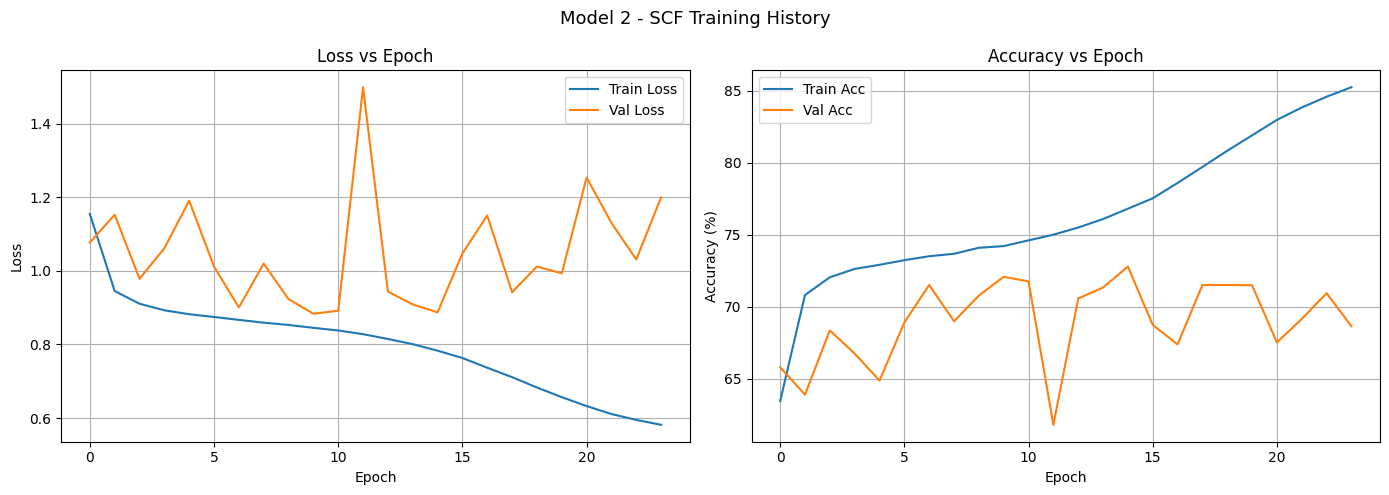

In [ ]:
# Cell 11 - Plot Training History

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
ax1.plot(train_losses, label="Train Loss")
ax1.plot(val_losses,   label="Val Loss")
ax1.set_title("Loss vs Epoch")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True)

# Accuracy curves
ax2.plot([a*100 for a in train_accs], label="Train Acc")
ax2.plot([a*100 for a in val_accs],   label="Val Acc")
ax2.set_title("Accuracy vs Epoch")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.legend()
ax2.grid(True)

plt.suptitle("Model 2 - SCF Training History", fontsize=13)
plt.tight_layout()
plt.show()

# statistical scores you can go.

for evaluation, make sure to use macro f1 instead of f1 - because some modulation types have worse classification ability at the same low snr compared to others type shi

In [ ]:
all_preds = []
all_labels = []
all_snrs = []
all_conf = []
all_true_prob = []
all_entropy = []

model.eval()
with torch.no_grad():
    for inputs, labels_batch, snrs_batch in test_loader:
        inputs = inputs.to(device)
        labels_dev = labels_batch.to(device)

        outputs = model(inputs)
        probs = torch.softmax(outputs, dim = 1)

        preds = probs.argmax(dim = 1)
        conf = probs.max(dim = 1).values
        true_prob = probs[torch.arange(probs.shape[0]), labels_dev]
        entropy = -(probs * torch.log(probs + 1e-12)).sum(dim = 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels_batch.numpy())
        all_snrs.extend(snrs_batch.numpy())
        all_conf.extend(conf.cpu().numpy())
        all_true_prob.extend(true_prob.cpu().numpy())
        all_entropy.extend(entropy.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_snrs = np.array(all_snrs)
all_conf = np.array(all_conf)
all_true_prob = np.array(all_true_prob)
all_entropy = np.array(all_entropy)

print("Done. Test samples:", len(all_preds))

Done. Test samples: 51917


In [ ]:
# rebuilding the metrics that the new eval loop no longer computes
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

overall_acc = accuracy_score(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average = 'macro')

print(f"Overall Accuracy: {overall_acc*100:.2f}%")
print(f"F1 Score (the macro one) : {macro_f1:.4f}")
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names = MOD_LABELS, digits = 3))

snr_range = sorted(np.unique(all_snrs).tolist())
snr_accs = {}

for snr in snr_range:
    mask = all_snrs == snr
    snr_acc = accuracy_score(all_labels[mask], all_preds[mask])
    snr_accs[snr] = snr_acc
    print(f"SNR {snr:4d} dB | Acc: {snr_acc*100:.2f}%")

Overall Accuracy: 72.95%
F1 Score (the macro one) : 0.7088

Classification Report:
              precision    recall  f1-score   support

        BPSK      0.812     0.794     0.803      3994
        QPSK      0.173     0.037     0.061      3993
        8PSK      0.440     0.719     0.546      3988
       16QAM      0.466     0.510     0.487      3994
       64QAM      0.576     0.356     0.440      3996
        PAM4      0.755     0.800     0.777      3992
        GFSK      0.712     0.928     0.806      3994
       CPFSK      0.804     0.805     0.805      3995
        2FSK      0.905     0.958     0.930      3996
        4FSK      0.847     0.808     0.827      3994
        B-FM      0.800     0.855     0.827      3992
      AM-DSB      0.968     0.964     0.966      3998
      AM-SSB      0.929     0.948     0.938      3991

    accuracy                          0.729     51917
   macro avg      0.707     0.729     0.709     51917
weighted avg      0.707     0.729     0.709     519

In [ ]:
correct = (all_preds == all_labels)

print(f"Mean confidence (all)     : {all_conf.mean():.3f}")
print(f"Mean confidence (correct) : {all_conf[correct].mean():.3f}")
print(f"Mean confidence (wrong)   : {all_conf[~correct].mean():.3f}")
print(f"Mean prob on true class   : {all_true_prob.mean():.3f}")
print(f"Mean entropy              : {all_entropy.mean():.3f}")
print(f"  ln(6)  = {np.log(6):.3f}  (uncertain across 6 classes)")
print(f"  ln(13) = {np.log(13):.3f}  (no idea at all)")

Mean confidence (all)     : 0.735
Mean confidence (correct) : 0.860
Mean confidence (wrong)   : 0.397
Mean prob on true class   : 0.687
Mean entropy              : 0.734
  ln(6)  = 1.792  (uncertain across 6 classes)
  ln(13) = 2.565  (no idea at all)


In [ ]:
high = (all_snrs >= 20)

print("High SNR only (>= 20 dB)")
print("Class      Acc      Conf    TrueP   Entropy")
for i in range(13):
    mask = (all_labels == i) & high
    acc_i = (all_preds[mask] == all_labels[mask]).mean()
    conf_i = all_conf[mask].mean()
    true_i = all_true_prob[mask].mean()
    ent_i = all_entropy[mask].mean()
    print(f"{MOD_LABELS[i]:8s} {acc_i*100:6.2f}%   {conf_i:.3f}   {true_i:.3f}   {ent_i:.3f}")

High SNR only (>= 20 dB)
Class      Acc      Conf    TrueP   Entropy
BPSK      99.57%   0.960   0.959   0.244
QPSK       1.08%   0.492   0.459   0.912
8PSK      97.07%   0.492   0.484   0.911
16QAM     70.22%   0.571   0.511   0.972
64QAM     51.41%   0.582   0.477   0.911
PAM4     100.00%   0.974   0.974   0.187
GFSK     100.00%   0.980   0.980   0.145
CPFSK    100.00%   0.968   0.968   0.214
2FSK     100.00%   0.969   0.969   0.212
4FSK     100.00%   0.969   0.969   0.215
B-FM     100.00%   0.973   0.973   0.188
AM-DSB   100.00%   0.953   0.953   0.301
AM-SSB    99.78%   0.956   0.955   0.282


In [ ]:
for snr in sorted(np.unique(all_snrs)):
    mask = (all_snrs == snr)
    acc_s = (all_preds[mask] == all_labels[mask]).mean()
    conf_s = all_conf[mask].mean()
    ent_s = all_entropy[mask].mean()
    print(f"SNR {snr:4d} dB | Acc: {acc_s*100:5.2f}% | Conf: {conf_s:.3f} | Entropy: {ent_s:.3f}")

SNR  -20 dB | Acc: 19.03% | Conf: 0.321 | Entropy: 1.982
SNR  -18 dB | Acc: 25.44% | Conf: 0.369 | Entropy: 1.827
SNR  -16 dB | Acc: 32.01% | Conf: 0.434 | Entropy: 1.635
SNR  -14 dB | Acc: 39.71% | Conf: 0.488 | Entropy: 1.462
SNR  -12 dB | Acc: 46.25% | Conf: 0.537 | Entropy: 1.300
SNR  -10 dB | Acc: 57.14% | Conf: 0.618 | Entropy: 1.076
SNR   -8 dB | Acc: 69.13% | Conf: 0.693 | Entropy: 0.867
SNR   -6 dB | Acc: 75.33% | Conf: 0.750 | Entropy: 0.697
SNR   -4 dB | Acc: 80.71% | Conf: 0.784 | Entropy: 0.599
SNR   -2 dB | Acc: 82.72% | Conf: 0.807 | Entropy: 0.522
SNR    0 dB | Acc: 83.85% | Conf: 0.819 | Entropy: 0.485
SNR    2 dB | Acc: 83.68% | Conf: 0.825 | Entropy: 0.465
SNR    4 dB | Acc: 85.92% | Conf: 0.830 | Entropy: 0.449
SNR    6 dB | Acc: 85.23% | Conf: 0.832 | Entropy: 0.447
SNR    8 dB | Acc: 85.05% | Conf: 0.831 | Entropy: 0.448
SNR   10 dB | Acc: 86.18% | Conf: 0.834 | Entropy: 0.442
SNR   12 dB | Acc: 86.22% | Conf: 0.831 | Entropy: 0.448
SNR   14 dB | Acc: 85.44% | Con

In [ ]:
bin_edges = [0.0, 0.2, 0.4, 0.6, 0.8, 1.01]

print("Conf range    n       Accuracy   Mean conf")
for b in range(5):
    lo = bin_edges[b]
    hi = bin_edges[b + 1]
    mask = (all_conf >= lo) & (all_conf < hi)
    n = mask.sum()
    if n > 0:
        print(f"{lo:.1f} - {hi:.1f}   {n:6d}   {correct[mask].mean()*100:6.2f}%    {all_conf[mask].mean():.3f}")

Conf range    n       Accuracy   Mean conf
0.0 - 0.2     2901    11.24%    0.164
0.2 - 0.4     5613    21.59%    0.291
0.4 - 0.6    10463    47.68%    0.501
0.6 - 0.8     3090    63.24%    0.669
0.8 - 1.0    29850    98.47%    0.963


CONFUSION OF THE MATRIX BECAUSE THE MATRIX IS CONFUSING

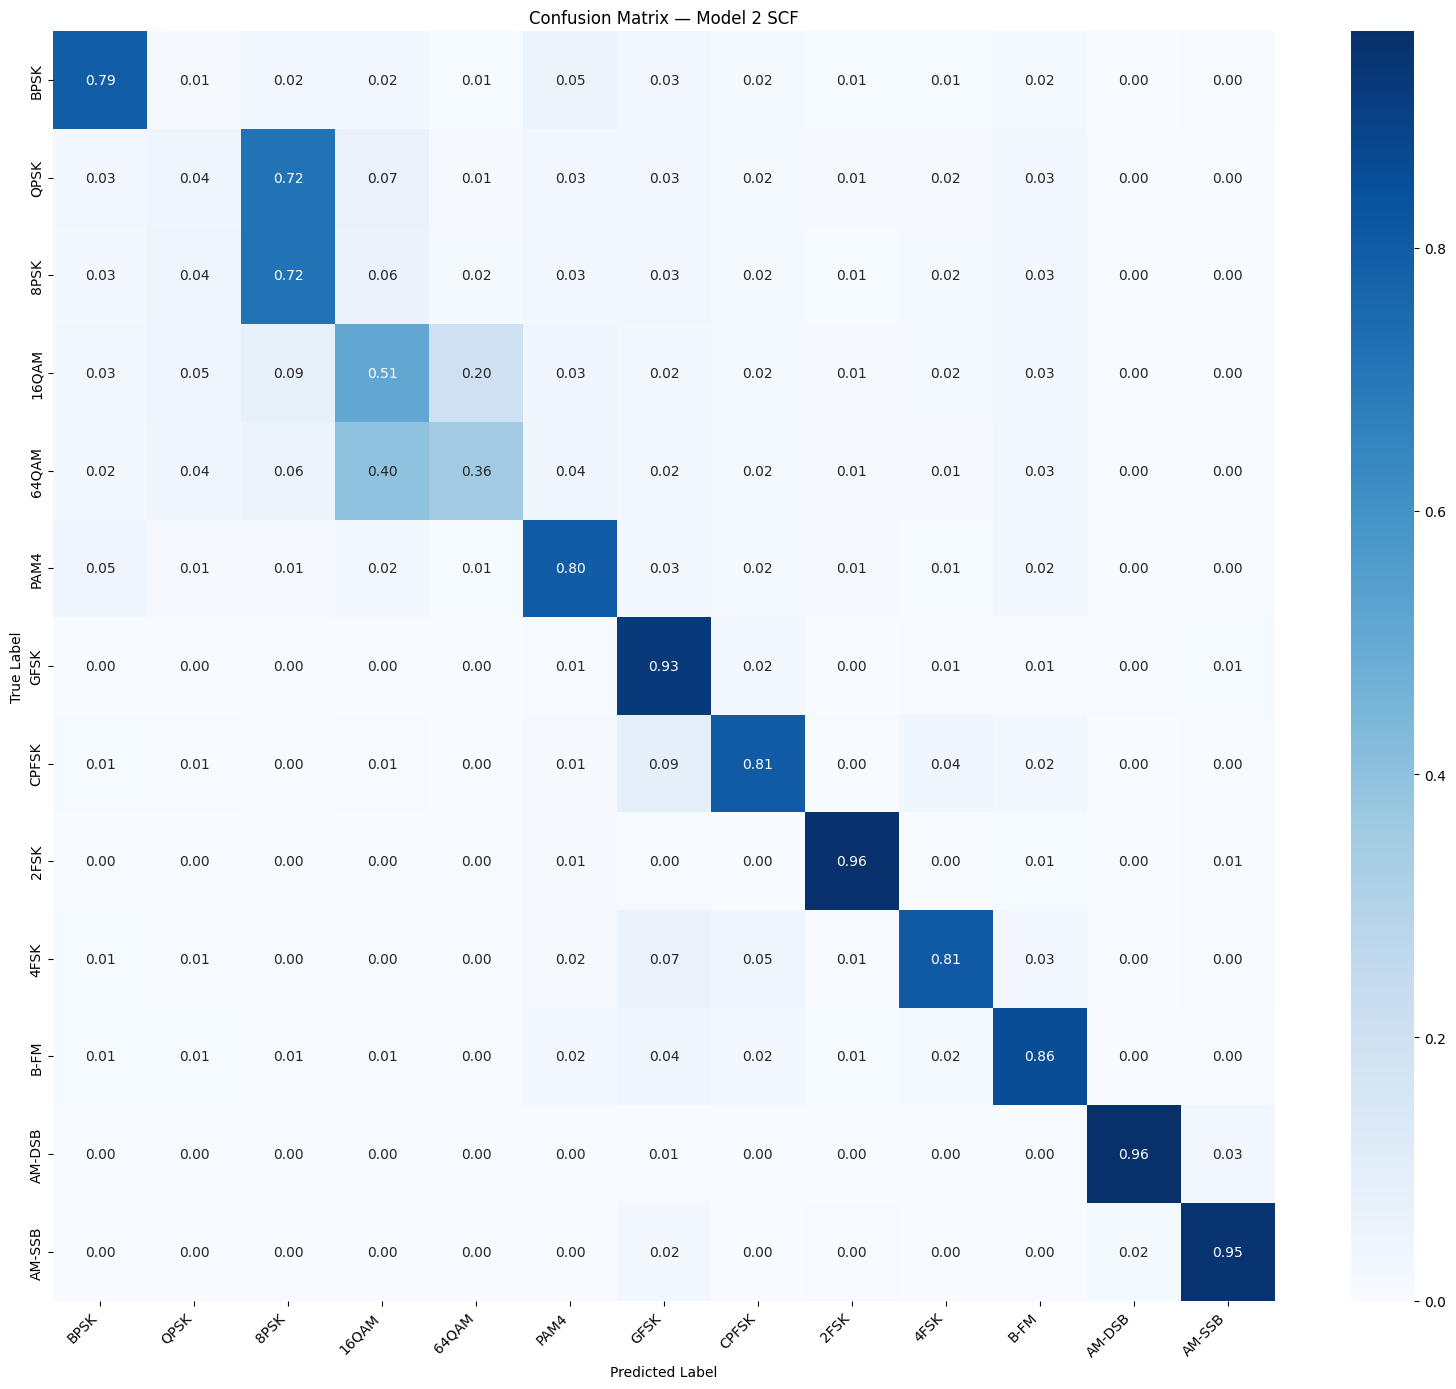

In [ ]:
# Confusion Matrix

cm = confusion_matrix(all_labels, all_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(16, 14))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=MOD_LABELS, yticklabels=MOD_LABELS)
plt.title("Confusion Matrix — Model 2 SCF")
plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

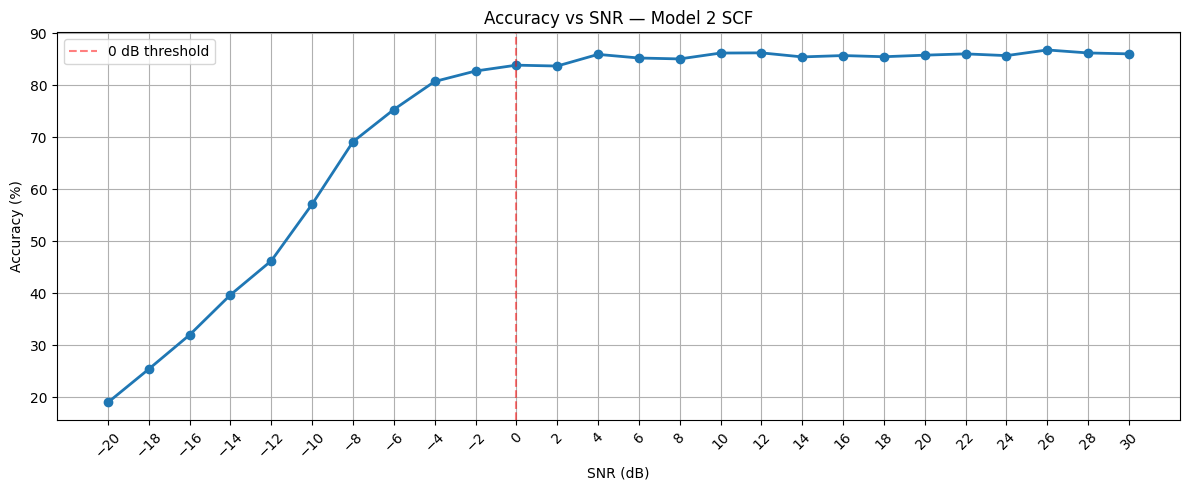

In [ ]:
# Accuracy vs SNR Plot

# x = snr and y is acc -> depend and independent stuff

snrs_sorted = sorted(snr_accs.keys())
accs = [snr_accs[s]*100 for s in snrs_sorted]

plt.figure(figsize=(12, 5))
plt.plot(snrs_sorted, accs, marker='o', linewidth=2)
plt.axvline(x=0, color='red', linestyle='--', alpha=0.5, label='0 dB threshold')
plt.title("Accuracy vs SNR — Model 2 SCF")
plt.xlabel("SNR (dB)")
plt.ylabel("Accuracy (%)")
plt.xticks(snrs_sorted, rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
hi = np.where(snrs >= 20)[0]
means = {}
for c in range(13):
    idx = hi[labels[hi] == c][:500]
    means[c] = X_loaded[idx].mean(0)

import itertools
print("within linear group:")
for a, b in itertools.combinations([0,1,2,3,4,5], 2):
    print(f"  {MOD_LABELS[a]:6s} vs {MOD_LABELS[b]:6s}: {np.abs(means[a]-means[b]).mean():.5f}")
print("across groups:")
for a, b in [(0,8), (0,11), (6,8)]:
    print(f"  {MOD_LABELS[a]:6s} vs {MOD_LABELS[b]:6s}: {np.abs(means[a]-means[b]).mean():.5f}")

within linear group:
  BPSK   vs QPSK  : 0.00624
  BPSK   vs 8PSK  : 0.00656
  BPSK   vs 16QAM : 0.00626
  BPSK   vs 64QAM : 0.00635
  BPSK   vs PAM4  : 0.00449
  QPSK   vs 8PSK  : 0.00138
  QPSK   vs 16QAM : 0.00180
  QPSK   vs 64QAM : 0.00183
  QPSK   vs PAM4  : 0.00558
  8PSK   vs 16QAM : 0.00180
  8PSK   vs 64QAM : 0.00187
  8PSK   vs PAM4  : 0.00565
  16QAM  vs 64QAM : 0.00109
  16QAM  vs PAM4  : 0.00499
  64QAM  vs PAM4  : 0.00490
across groups:
  BPSK   vs 2FSK  : 0.06241
  BPSK   vs AM-DSB: 0.11781
  GFSK   vs 2FSK  : 0.09319


In [ ]:
np.savez(os.path.join(save_dir, "scf_8192_eval.npz"),      # scf_v2_eval.npz in the SCF notebook
         preds = all_preds,
         labels = all_labels,
         snrs = all_snrs,
         conf = all_conf,
         true_prob = all_true_prob,
         entropy = all_entropy,
         probs = all_probs)

print("Saved.", all_probs.shape)

NameError: name 'all_probs' is not defined